### Задание 1(Вариант 1)
Даны независимые выборки $X_1,\dots,X_n \sim \mathcal N(\mu_1,\sigma_1^2)$ и $Y_1,\dots,Y_m \sim \mathcal N(\mu_2,\sigma_2^2)$ с известными дисперсиями. Построить доверительный интервал для $\tau=\mu_1-\mu_2$ и исследовать его при разных $n,m$.

В эксперименте: $\mu_1=2$, $\mu_2=1$, $\sigma_1^2=1$, $\sigma_2^2=0.5$, поэтому $\tau=1$; $\alpha=0.05$, число повторений — $10000$.

### Построение интервала
Используем оценку $\widehat\tau=\overline X-\overline Y$. По нормальности и независимости:
$$
\widehat\tau\sim\mathcal N\left(\tau,\frac{\sigma_1^2}{n}+\frac{\sigma_2^2}{m}\right)
$$
$$
Z=\frac{\widehat\tau-\tau}{\sqrt{\sigma_1^2/n+\sigma_2^2/m}}
\sim\mathcal N(0,1)
$$

Пусть $z_{1-\alpha/2}=\Phi^{-1}(1-\alpha/2)$. Тогда
$$
P\left(-z_{1-\alpha/2}\le Z\le z_{1-\alpha/2}\right)=1-\alpha
$$

Отсюда точный доверительный интервал уровня $0.95$:
$$
[L,U]=\left[
\widehat\tau-r,\;
\widehat\tau+r
\right]
$$
$$
r=\Phi^{-1}(0.975)\sqrt{\frac1n+\frac{0.5}{m}}
$$

In [3]:
import numpy as np
from scipy.stats import norm
import math

rng = np.random.default_rng(123)
mu1 = 2
mu2 = 1
tau = mu1 - mu2
sigma1 = 1
sigma2 = math.sqrt(0.5)
numberOfExp = 10000
alpha = 0.05

def exp1(n, m):
    samples1 = rng.normal(mu1, sigma1, (numberOfExp, n))
    samples2 = rng.normal(mu2, sigma2, (numberOfExp, m))
    m1 = samples1.mean(axis=1)
    m2 = samples2.mean(axis=1)
    estimate = m1 - m2
    r = norm.ppf(1 - alpha / 2) * math.sqrt(sigma1 ** 2 / n + sigma2 ** 2 / m)
    lowerBounds = estimate - r
    upperBounds = estimate + r
    cov = np.mean((lowerBounds <= tau) & (tau <= upperBounds))
    width = np.mean(upperBounds - lowerBounds)
    print(f"{n:5d} {m:5d} {cov:10.4f} {lowerBounds.mean():13.6f} {upperBounds.mean():13.6f} {width:13.6f}")

groups = {"n = m": [(10, 10), (50, 50), (100, 100), (500, 500), (1000, 1000)], 
          "n + m = fixed": [(10, 990), (100, 900), (500, 500), (586, 414), (900, 100), (990, 10)]}

for name, sizes in groups.items():
    print(f"\ngroup: {name}")
    print("-"*73)
    print(f"{'n':>5} {'m':>5} {'coverage':>10} {'mean lower':>13} {'mean upper':>13} {'mean width':>13}")
    print("-"*73)
    for n, m in sizes:
        exp1(n, m)



group: n = m
-------------------------------------------------------------------------
    n     m   coverage    mean lower    mean upper    mean width
-------------------------------------------------------------------------
   10    10     0.9537      0.245076      1.763258      1.518182
   50    50     0.9442      0.660577      1.339528      0.678951
  100   100     0.9511      0.763146      1.243238      0.480091
  500   500     0.9539      0.893032      1.107735      0.214703
 1000  1000     0.9511      0.924101      1.075919      0.151818

group: n + m = fixed
-------------------------------------------------------------------------
    n     m   coverage    mean lower    mean upper    mean width
-------------------------------------------------------------------------
   10   990     0.9531      0.383690      1.626406      1.242716
  100   900     0.9512      0.798240      1.200974      0.402734
  500   500     0.9517      0.892824      1.107527      0.214703
  586   414     0.

### Как проводился эксперимент
Для каждой пары $(n,m)$ генерировались `numberOfExp = 10000` независимых пар выборок.

Далее вычислялись выборочные средние `m1`, `m2`, оценка разности `estimate = m1 - m2`.

Радиус интервала рассчитывался как

`r = norm.ppf(1 - alpha / 2) * math.sqrt(sigma1 ** 2 / n + sigma2 ** 2 / m)`.

В таблицу выводились:
- `coverage` — доля интервалов, содержащих истинное значение `tau = 1`
- `mean lower` и `mean upper` — средние границы
- `mean width` — средняя ширина интервала

Сравнивались пары из групп `n = m` и `n + m = 1000`. Использовался сид `123`.

### Интерпретация результатов
Во всех экспериментах доля интервалов, содержащих истинное значение `tau = 1`, как и ожидалось близка к заданному уровню $0.95$.

При `n = m` увеличение объёмов с `10` до `1000` уменьшает ширину интервала примерно в `10` раз с `1.5182` до `0.1518`, это объясняется тем что ширина примерно равна $2\cdot1.96\sqrt{1.5/n}$ и убывает как $1/\sqrt n$

При `n + m = 1000` минимальный интервал достигается при `n, m = (586, 414)`. Доказательство: радиус зависит от суммы $\frac1n+\frac{0.5}{m}$. Найдём минимум этой функции при $n+m=1000$, подставим $m=1000-n$:
$$
f(n)=\frac1n+\frac{0.5}{1000-n}
$$

$$
f'(n)=-\frac1{n^2}+\frac{0.5}{(1000-n)^2}=0
$$

$$
n_*=\frac{1000\sqrt2}{1+\sqrt2}\approx586.78,
\qquad
m_*=\frac{1000}{1+\sqrt2}\approx414.21
$$

Значит минимальная ширина интервала достигается при $(n,m)=(586,414)$. Это подтверждается результатом эксперимента.

Также для `(900, 100)` интервал уже, чем для `(100, 900)`. Это объясняется тем, что первая выборка имеет большую дисперсию, поэтому увеличение её объёма сильнее снижает дисперсию оценки.

Таким образом, изменение объёмов выборок влияет на точность оценивания, а покрытие остаётся близким к $0.95$.


# Задание 2 — Вариант 4

$X_1, X_2, \ldots, X_n \sim \operatorname{Geom}(p)$

$$
P(X_i=k)=p(1-p)^k,\quad k=0,1,2,\ldots
$$

## Асимптотический доверительный интервал используя асимптотическую нормальность выборочного среднего

$$
\mathbb{E}X = \frac{1-p}{p},
\qquad
\operatorname{Var}(X) = \frac{1-p}{p^2}
$$

По ЦПТ:

$$
\frac{\sqrt{n}(\overline{X}-\frac{1-p}{p})}
{\sqrt{\frac{1-p}{p^2}}}
\xrightarrow{d}\mathcal{N}(0,1)
$$

Выборочная дисперсия:

$$
S^{*2}=\frac{1}{n}\sum_{i=1}^{n}(X_i-\overline{X})^2
$$

По ЗБЧ:

$$
\overline{X}\xrightarrow{P}\mathbb{E}X_i,
\qquad
\overline{X^2}\xrightarrow{P}\mathbb{E}X_i^2
$$

$$
S^{*2}=\overline{X^2}-\overline{X}^2
$$

$$
S^{*2}\xrightarrow{P}
\mathbb{E}X_i^2-(\mathbb{E}X_i)^2
=\operatorname{Var}(X_i)
$$

По непрерывности квадратного корня:

$$
S^*\xrightarrow{P}\sqrt{\frac{1-p}{p^2}}
$$

По теореме Слуцкого:

$$
\frac{\sqrt{n}(\overline{X}-\frac{1-p}{p})}{S^*}
\xrightarrow{d}\mathcal{N}(0,1)
$$

$q_{1-\alpha/2}$ — квантиль $\mathcal{N}(0,1)$, тогда

$$
P\left(
-q_{1-\alpha/2}
\le
\frac{\sqrt{n}(\overline{X}-\frac{1-p}{p})}{S^*}
\le
q_{1-\alpha/2}
\right)
\longrightarrow 1-\alpha
$$

Выразим $\frac{1-p}{p}$:

$$
P\left(
\overline{X}-\frac{q_{1-\alpha/2}S^*}{\sqrt{n}}
\le
\frac{1-p}{p}
\le
\overline{X}+\frac{q_{1-\alpha/2}S^*}{\sqrt{n}}
\right)
\longrightarrow 1-\alpha
$$

$$
P\left(
1+\overline{X}-\frac{q_{1-\alpha/2}S^*}{\sqrt{n}}
\le
\frac{1}{p}
\le
1+\overline{X}+\frac{q_{1-\alpha/2}S^*}{\sqrt{n}}
\right)
\longrightarrow 1-\alpha
$$

Выразим $p$:

$$
\left[
\frac{1}{1+\overline{X}+\frac{q_{1-\alpha/2}S^*}{\sqrt{n}}};
\frac{1}{1+\overline{X}-\frac{q_{1-\alpha/2}S^*}{\sqrt{n}}}
\right]
$$

При $1+\overline{X}-\frac{q_{1-\alpha/2}S^*}{\sqrt{n}}\ge 1$. В противном случае верхняя граница интервала равна $1$.



## Асимптотический доверительный интервал используя асимптотическую нормальность максимального правдоподобия

$$
P(X_i=k)=p(1-p)^k,\quad k=0,1,2,\ldots
$$

Функция правдоподобия:

$$
L(p)=\prod_{i=1}^{n}p(1-p)^{X_i}
=p^n(1-p)^{\sum_{i=1}^n X_i}
$$

Логарифмируем:

$$
l(p)=n\ln p+\sum_{i=1}^n X_i\ln(1-p)
$$

Найдем максимум:

$$
l'(p)=\frac{n}{p}-\frac{\sum_{i=1}^n X_i}{1-p}=0
$$

$$
n(1-p)=p\sum_{i=1}^n X_i
$$

$$
\hat p=\frac{n}{n+\sum_{i=1}^n X_i}
=\frac{1}{1+\overline X}
$$

$$
l''(p)=-\frac{n}{p^2}-\frac{\sum_{i=1}^n X_i}{(1-p)^2}
$$

Информация Фишера:

$$
I_n(p)=-\mathbb E[l''(p)]
$$

$$
I_n(p)=\frac{n}{p^2}+
\frac{\mathbb E[\sum_{i=1}^n X_i]}{(1-p)^2}
$$

Так как $\mathbb EX_i=\frac{1-p}{p}$:

$$
I_n(p)=\frac{n}{p^2}+
\frac{n(1-p)}{p(1-p)^2}
$$

$$
I_n(p)=\frac{n}{p^2}+\frac{n}{p(1-p)}
=\frac{n}{p^2(1-p)}
$$

Информация Фишера одного наблюдения:

$$
I(p)=\frac{I_n(p)}{n}=\frac{1}{p^2(1-p)}
$$

По асимптотической нормальности:

$$
\sqrt n(\hat p-p)
\xrightarrow{d}
\mathcal N\left(0,\frac{1}{I(p)}\right)
$$

$$
\frac{\sqrt n(\hat p-p)}{p\sqrt{1-p}}
\xrightarrow{d}\mathcal N(0,1)
$$

По состоятельности:

$$
\hat p\xrightarrow{P}p
$$

По теореме Слуцкого:

$$
\frac{\sqrt n(\hat p-p)}
{\hat p\sqrt{1-\hat p}}
\xrightarrow{d}\mathcal N(0,1)
$$

$q_{1-\alpha/2}$ — квантиль $\mathcal N(0,1)$, тогда

$$
P\left(
-q_{1-\alpha/2}
\le
\frac{\sqrt n(\hat p-p)}
{\hat p\sqrt{1-\hat p}}
\le
q_{1-\alpha/2}
\right)
\longrightarrow 1-\alpha
$$

Выразим $p$:

$$
P\left(
\hat p-q_{1-\alpha/2}\hat p\sqrt{\frac{1-\hat p}{n}}
\le p\le
\hat p+q_{1-\alpha/2}\hat p\sqrt{\frac{1-\hat p}{n}}
\right)
\longrightarrow 1-\alpha
$$

$$
\left[
\hat p-q_{1-\alpha/2}\hat p\sqrt{\frac{1-\hat p}{n}};
\hat p+q_{1-\alpha/2}\hat p\sqrt{\frac{1-\hat p}{n}}
\right]
$$

Где

$$
\hat p=\frac{1}{1+\overline X}
$$



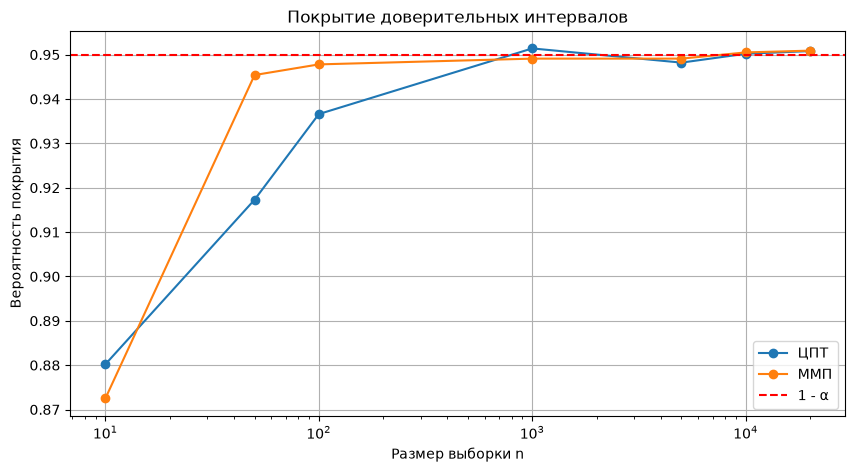

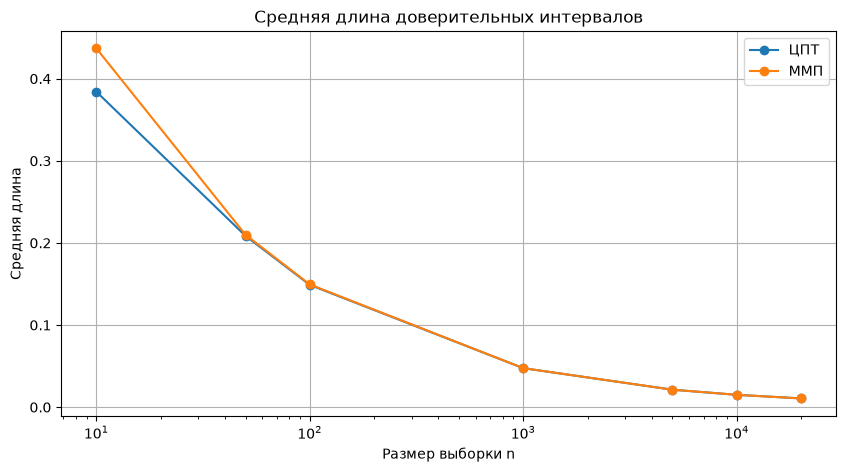

In [3]:
import numpy as np
from scipy.stats import norm
import math
import matplotlib.pyplot as plt

p = 0.7
N = 10000
a = 0.05
sizes = [10, 50, 100, 1000, 5000, 10000, 20000]

rng = np.random.default_rng(6767676767)

coverages1 = []
coverages2 = []
lengths1 = []
lengths2 = []

for n in sizes:
    samples = rng.geometric(p, size=(N, n)) - 1
    mean = np.mean(samples, axis=1)
    var = np.var(samples, axis=1)

    qant = norm.ppf(1 - a / 2)

    qd = qant * np.sqrt(var / n)

    l1 = 1 / (1 + mean + qd)
    r1 = 1 / np.maximum(1, 1 + mean - qd)

    pd = 1 / (1 + mean)
    l2 = pd - qant * pd * np.sqrt((1 - pd)/ n)
    r2 = pd + qant * pd * np.sqrt((1 - pd)/ n)

    res1 = np.mean((l1 <= p) & (p <= r1))
    res2 = np.mean((l2 <= p) & (p <= r2))

    len1 = np.mean(r1 - l1)
    len2 = np.mean(r2 - l2)

    coverages1.append(res1)
    coverages2.append(res2)
    lengths1.append(len1)
    lengths2.append(len2)


plt.figure(figsize=(10, 5))

plt.plot(sizes, coverages1, marker='o', label='ЦПТ')
plt.plot(sizes, coverages2, marker='o', label='ММП')
plt.axhline(1 - a, color='red', linestyle='--', label='1 - α')

plt.xscale('log')
plt.xlabel('Размер выборки n')
plt.ylabel('Вероятность покрытия')
plt.title('Покрытие доверительных интервалов')
plt.legend()
plt.grid(True)
plt.show()


plt.figure(figsize=(10, 5))

plt.plot(sizes, lengths1, marker='o', label='ЦПТ')
plt.plot(sizes, lengths2, marker='o', label='ММП')

plt.xscale('log')
plt.xlabel('Размер выборки n')
plt.ylabel('Средняя длина')
plt.title('Средняя длина доверительных интервалов')
plt.legend()
plt.grid(True)
plt.show()
